# Morphological measures: describing a body with numbers

`MorphologicalMeasures` takes the graph of a robot body (a core with bricks and hinges attached to its faces) and turns its shape into numbers between 0 and 1: how branched it is, how many limbs it has, how symmetric it is, how much of its bounding box it fills, and so on. Evolution can use these numbers as a fitness or as a way to compare bodies.

In this notebook you build six bodies, draw each one from above, and read their measures from one table. The pictures and the numbers should agree: a snake is long and thin, a cross is symmetric. No graphics backend is needed.

In [1]:
# Standard library
import math
import random

In [2]:
# Third-party libraries
import matplotlib.pyplot as plt
from rich.table import Table

In [3]:
# Local libraries
from ariel import console
from ariel.body_phenotypes import MorphologicalMeasures
from ariel.ec.genotypes.tree import TreeGenome, random_tree
from ariel.ec.genotypes.tree.tree_genome import TreeEdge, TreeNode

In [4]:
# Seed
SEED = 42
random.seed(SEED)
MEASURES = (
    "branching",
    "limbs",
    "length_of_limbs",
    "coverage",
    "proportion",
    "symmetry",
    "joints",
    "size",
    "module_diversity",
)

## Six bodies

A body is a `TreeGenome`: nodes with a module type (CORE, BRICK, HINGE) and edges that name the face of the parent the child is attached to. The first five are built by hand so their shape is known; the last is random.

In [5]:
def body(
    types: dict[int, str], edges: list[tuple[int, int, str]]
) -> TreeGenome:
    return TreeGenome(
        nodes={i: TreeNode(type=t, rotation="DEG_0") for i, t in types.items()},
        edges=[TreeEdge(parent=p, child=c, face=f) for p, c, f in edges],
    )


bodies = {
    "core only": body({0: "CORE"}, []),
    "snake": body(
        {0: "CORE", 1: "BRICK", 2: "HINGE", 3: "BRICK", 4: "BRICK"},
        [(0, 1, "FRONT"), (1, 2, "FRONT"), (2, 3, "FRONT"), (3, 4, "FRONT")],
    ),
    "cross": body(
        {0: "CORE", 1: "BRICK", 2: "BRICK", 3: "BRICK", 4: "BRICK"},
        [(0, 1, "FRONT"), (0, 2, "BACK"), (0, 3, "RIGHT"), (0, 4, "LEFT")],
    ),
    "walker": body(
        {
            0: "CORE",
            1: "HINGE",
            2: "BRICK",
            3: "BRICK",
            4: "BRICK",
            5: "BRICK",
            6: "BRICK",
        },
        [
            (0, 1, "FRONT"),
            (1, 2, "FRONT"),
            (0, 3, "RIGHT"),
            (3, 4, "RIGHT"),
            (0, 5, "LEFT"),
            (5, 6, "LEFT"),
        ],
    ),
    "lopsided": body(
        {0: "CORE", 1: "BRICK", 2: "BRICK", 3: "BRICK"},
        [(0, 1, "FRONT"), (1, 2, "RIGHT"), (2, 3, "RIGHT")],
    ),
    "random": random_tree(10),
}
measures = {
    name: MorphologicalMeasures(genome.to_networkx())
    for name, genome in bodies.items()
}
console.print({name: len(genome.nodes) for name, genome in bodies.items()})

{'core only': 1, 'snake': 5, 'cross': 5, 'walker': 7, 'lopsided': 4, 'random': 11}

## The bodies from above

Each module sits at a cell of a 3D grid. The picture shows the top-down view (front is to the right): red core, blue bricks, green hinges. Modules stacked above each other overlap.

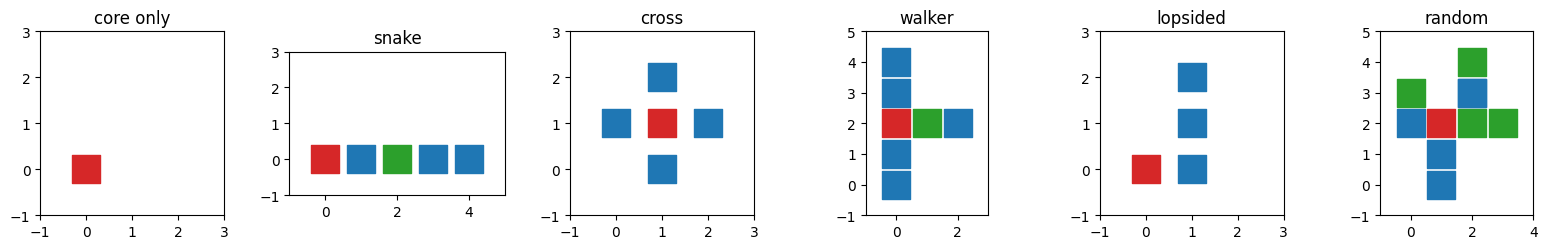

In [6]:
COLOURS = {"CORE": "tab:red", "BRICK": "tab:blue", "HINGE": "tab:green"}
fig, axes = plt.subplots(1, len(bodies), figsize=(16, 2.6))
for axis, (name, genome) in zip(axes, bodies.items(), strict=True):
    grid = measures[name].grid
    for x in range(grid.shape[0]):
        for y in range(grid.shape[1]):
            for z in range(grid.shape[2]):
                node = grid[x, y, z]
                if node is not None:
                    axis.scatter(
                        x,
                        y,
                        s=400,
                        marker="s",
                        color=COLOURS[genome.nodes[node].type],
                    )
    axis.set_xlim(-1, max(grid.shape[0], 3))
    axis.set_ylim(-1, max(grid.shape[1], 3))
    axis.set_aspect("equal")
    axis.set_title(name)
plt.tight_layout()
plt.show()

## The measures side by side

Every measure is between 0 and 1. Read the table against the pictures: the snake has one long limb and no symmetry, the cross is fully symmetric, the walker is the only one with a joint besides the snake.

In [7]:
table = Table(title="Morphological measures")
table.add_column("body")
for measure in MEASURES:
    table.add_column(
        measure.replace("_", " "), justify="right", overflow="fold"
    )
for name, result in measures.items():
    table.add_row(name, *(f"{getattr(result, m):.2f}" for m in MEASURES))
console.print(table)

                                              Morphological measures                                               
┏━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━┳━━━━━━┳━━━━━━━━━━━━━━┓
┃           ┃           ┃       ┃     length of ┃          ┃            ┃          ┃        ┃      ┃       module ┃
┃ body      ┃ branching ┃ limbs ┃         limbs ┃ coverage ┃ proportion ┃ symmetry ┃ joints ┃ size ┃    diversity ┃
┡━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━╇━━━━━━╇━━━━━━━━━━━━━━┩
│ core only │      0.00 │  0.00 │          0.00 │     1.00 │       1.00 │     0.00 │   0.00 │ 1.00 │         0.00 │
│ snake     │      0.00 │  0.25 │          1.00 │     1.00 │       0.20 │     0.00 │   0.25 │ 1.00 │         0.67 │
│ cross     │      0.00 │  1.00 │          0.00 │     0.56 │       1.00 │     1.00 │   0.00 │ 0.56 │         0.00 │
│ walker    │      0.00 │  0.60 │          0.60 │     0.47 │       0.60 │     1.00 │   0.17 │ 0.47 │         0.33 │
│ lopsided  │      0.00 │  0.33 │          1.00 │     0.67 │       0.67 │     0.00 │   0.00 │ 0.67 │         0.00 │
│ random    │      0.00 │  0.75 │          0.22 │     0.28 │       0.80 │     0.00 │   0.40 │ 0.28 │         0.57 │
└───────────┴───────────┴───────┴───────────────┴──────────┴────────────┴──────────┴────────┴──────┴──────────────┘

In [8]:
for result in measures.values():
    for measure in MEASURES:
        assert 0.0 <= getattr(result, measure) <= 1.0
assert measures["core only"].limbs == 0
assert measures["core only"].symmetry == 0
assert math.isclose(measures["cross"].symmetry, 1.0)
assert measures["snake"].symmetry == 0
assert math.isclose(measures["snake"].length_of_limbs, 1.0)
assert measures["walker"].joints > measures["cross"].joints
assert measures["walker"].symmetry > measures["lopsided"].symmetry

## Bad input is an error you can read

A graph whose edge has no valid face cannot be placed on the grid, so the measures refuse it and name the edge.

In [9]:
graph = bodies["cross"].to_networkx()
graph.edges[0, 1]["face"] = "UP"
try:
    MorphologicalMeasures(graph)
except ValueError as error:
    message = str(error)
console.print(message)
assert "0 -> 1" in message

Edge 0 -> 1 has no valid face ('UP'); valid faces are FRONT, BACK, RIGHT, LEFT, TOP, BOTTOM